# **TS - Classification**

In [1]:
# import numpy
# import scipy
# import sklearn
# import tslearn
# import mlxtend
# #from matrixprofile import matrixProfile
# #from matrixprofile import *
# import stumpy
import os


## **Motif** - Stumpy

In [2]:
import os
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Directory contenente le time series
time_series_dir = "../datasets/cleaned_times_series/"

# Liste per salvare i dataset delle time series e i relativi nomi
df_ts = []  # Ogni elemento è il dataset della time series di un paziente
df_name = []  # Contiene i nomi dei dataset nella lista df_ts

# Funzione per leggere un file CSV e convertirlo in DataFrame
def csv_to_df(file_name):
    file_path = os.path.join(time_series_dir, file_name)
    return pd.read_csv(file_path)

# Loop attraverso i file nella directory delle time series
for file_name in os.listdir(time_series_dir):
    if file_name.endswith(".csv"):
        df = csv_to_df(file_name)

        # Seleziona solo le colonne numeriche per la normalizzazione
        numeric_cols = df.select_dtypes(include=['number']).columns

        # Applica lo Standard Scaler di sklearn
        scaler = StandardScaler()
        df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

        df_ts.append(df)  # Aggiungi il DataFrame normalizzato alla lista
        df_name.append(file_name.split("_")[0])  # Salva il nome del file

# Stampa i file letti
print("File letti:", df_name)
print("Numero di file letti:", len(df_name))


File letti: ['10000032', '10000117', '10000764', '10000980', '10001176', '10001217', '10001401', '10002221', '10002430', '10002528', '10002557', '10002755', '10002807', '10002869', '10003019', '10003052', '10003199', '10003203', '10003299', '10003400', '10003757', '10004235', '10004322', '10004457', '10004606', '10004720', '10005606', '10005866', '10006023', '10006431', '10006457', '10006501', '10006692', '10006820', '10007058', '10008064', '10008647', '10008742', '10008816', '10009049', '10010231', '10010264', '10010471', '10010718', '10010920', '10011189', '10011365', '10011938', '10012438', '10012688', '10012853', '10013094', '10013310', '10013324', '10013502', '10013643', '10013724', '10013866', '10013970', '10014354', '10014378', '10014765', '10015057', '10015129', '10015132', '10015272', '10015367', '10015487', '10015568', '10015656', '10015701', '10015785', '10015931', '10016353', '10016374', '10016673', '10016742', '10016810', '10016828', '10017035', '10017308', '10017492', '10

In [32]:
df_ts[0].columns

Index(['I', 'II', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2', 'V3', 'V4', 'V5',
       'V6'],
      dtype='object')

### Motif Discovery


Finding motifs for lead: aVR


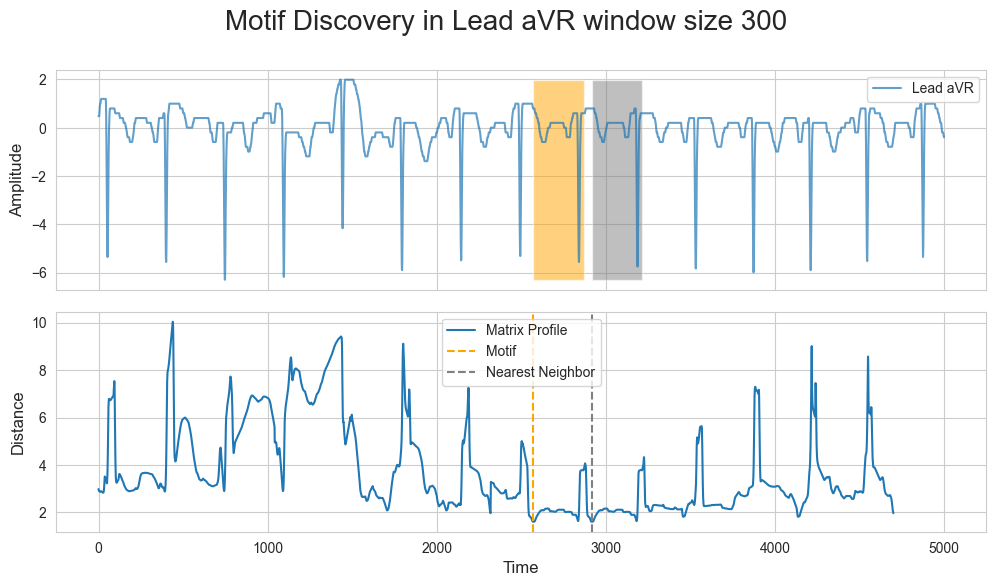


Finding motifs for lead: aVR


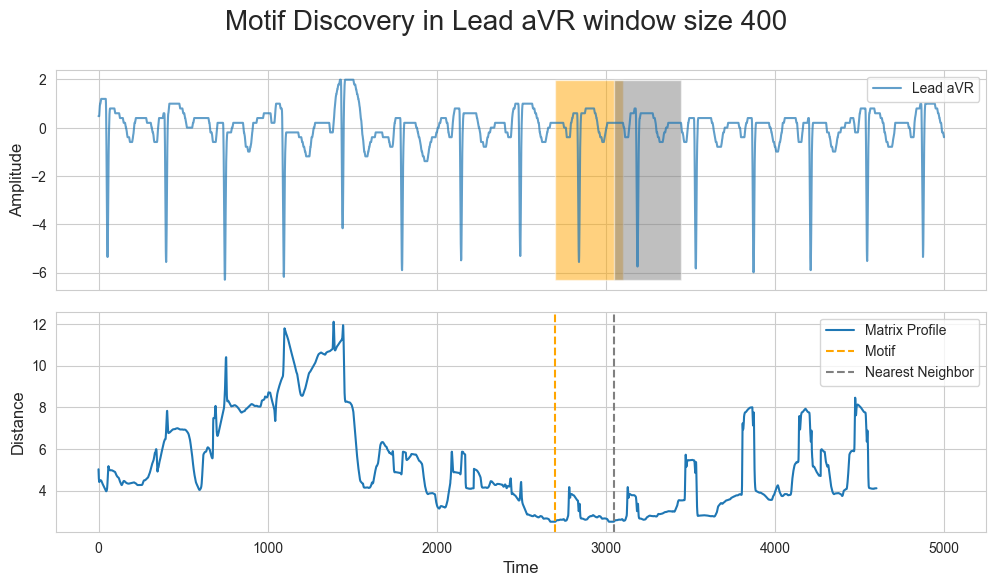


Finding motifs for lead: aVR


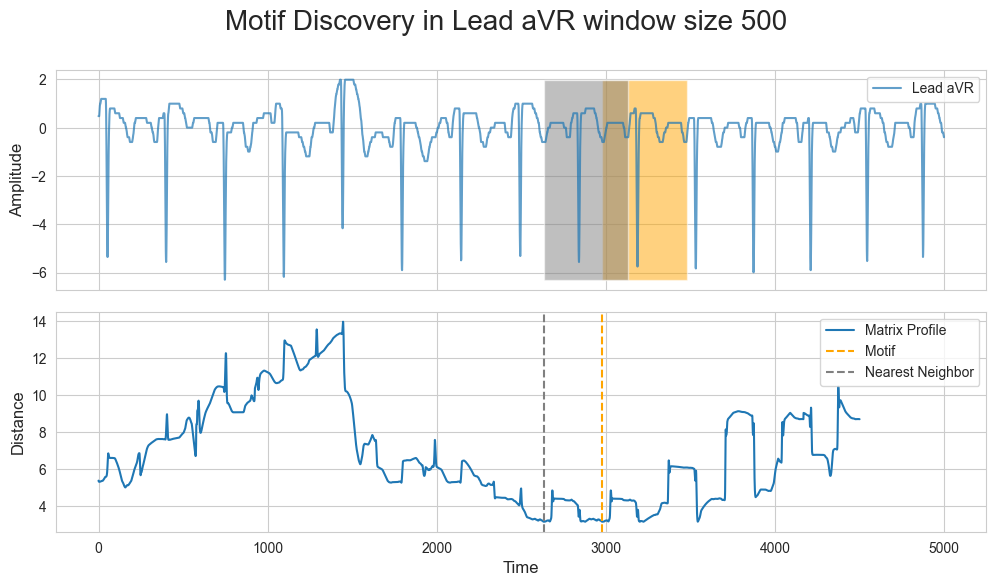

In [31]:
# Required Libraries
import os
import pandas as pd
import stumpy
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Define the 6 selected leads for analysis
selected_leads = ['aVR']

# Set motif window size
window_sizes = [300, 400, 500]  # Adjust based on signal sampling rate and desired motif length

for window_size in window_sizes:
    for df in df_ts[20:21]:
        # Loop through each selected lead
        for lead in selected_leads:
            if lead not in df.columns:
                print(f"Lead {lead} is missing in the file.")
                continue
            print(f"\nFinding motifs for lead: {lead}")
            # Extract the time series for the current lead
            ts_lead = df[lead].values
            # Perform motif discovery using STUMP
            mp = stumpy.stump(ts_lead, m=window_size)
            # Identify the motif and nearest neighbor indices
            motif_idx = np.argsort(mp[:, 0])[0]
            nearest_neighbor_idx = mp[motif_idx, 1]
            # Plot the motifs
            fig, axs = plt.subplots(2, sharex=True, gridspec_kw={'hspace': 0.1}, figsize=(12, 6))
            plt.suptitle(f"Motif Discovery in Lead {lead} window size {window_size}", fontsize=20)
            # Plot the time series with highlighted motifs
            axs[0].plot(ts_lead, alpha=0.7, label=f'Lead {lead}')
            rect1 = Rectangle((motif_idx, ts_lead.min()), window_size, ts_lead.ptp(), facecolor='orange', alpha=0.5)
            rect2 = Rectangle((nearest_neighbor_idx, ts_lead.min()), window_size, ts_lead.ptp(), facecolor='grey', alpha=0.5)
            axs[0].add_patch(rect1)
            axs[0].add_patch(rect2)
            axs[0].set_ylabel('Amplitude', fontsize=12)
            axs[0].legend()
            # Plot the Matrix Profile
            axs[1].plot(mp[:, 0], label='Matrix Profile', color='tab:blue')
            axs[1].axvline(x=motif_idx, linestyle="dashed", color='orange', label='Motif')
            axs[1].axvline(x=nearest_neighbor_idx, linestyle="dashed", color='grey', label='Nearest Neighbor')
            axs[1].set_xlabel('Time', fontsize=12)
            axs[1].set_ylabel('Distance', fontsize=12)
            axs[1].legend()
            plt.show()


viene scelta la window size 400

Registrazione dei valori del motif discovery per dopo (shapelet discovery)

In [35]:
import os
import pandas as pd
import stumpy
import numpy as np
# Define the 6 selected leads for analysis
selected_leads = ['I', 'II', 'III', 'aVR', 'aVF', 'aVL', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

# Set motif window sizes
window_size =400

# Lista per salvare i motif principali
motif_results = []

for idx, df in enumerate(df_ts):
    subject_id = df_name[idx].split('_')[0]
    print(idx, " | patient : ", subject_id)
    # Loop through each selected lead
    for lead in selected_leads:
        if lead not in df.columns:
            print(f"Lead {lead} is missing in the file.")
            continue
        # Extract te time series for the current lead
        ts_lead = df[lead].values
        # Perform motif discovery using STUMP
        mp = stumpy.stump(ts_lead, m=window_size)
        # Identify the motif and nearest neighbor indices
        motif_idx = np.argsort(mp[:, 0])[0]
        nearest_neighbor_idx = mp[motif_idx, 1]
        # Salva i risultati
        motif_results.append({
            'subject_id': subject_id,
            'lead': lead,
            'motif_idx': motif_idx,
            'nearest_neighbor_idx': nearest_neighbor_idx,
            'motif_distance': mp[motif_idx, 0]
        })
        # 1h 0m

0  | patient :  10000032
1  | patient :  10000117
2  | patient :  10000764
3  | patient :  10000980
4  | patient :  10001176
5  | patient :  10001217
6  | patient :  10001401
7  | patient :  10002221
8  | patient :  10002430
9  | patient :  10002528
10  | patient :  10002557
11  | patient :  10002755
12  | patient :  10002807
13  | patient :  10002869
14  | patient :  10003019
15  | patient :  10003052
16  | patient :  10003199
17  | patient :  10003203
18  | patient :  10003299
19  | patient :  10003400
20  | patient :  10003757
21  | patient :  10004235
22  | patient :  10004322
23  | patient :  10004457
24  | patient :  10004606
25  | patient :  10004720
26  | patient :  10005606
27  | patient :  10005866
28  | patient :  10006023
29  | patient :  10006431
30  | patient :  10006457
31  | patient :  10006501
32  | patient :  10006692
33  | patient :  10006820
34  | patient :  10007058
35  | patient :  10008064
36  | patient :  10008647
37  | patient :  10008742
38  | patient :  10008

In [37]:
motif_df = pd.DataFrame(motif_results)

motif_df.to_csv('motif_discovery_results.csv', index=False)

In [38]:
motif_df

,subject_id,lead,motif_idx,nearest_neighbor_idx,motif_distance
0,10000032,I,3945,648,3.556281
1,10000032,II,6,4299,1.344149
2,10000032,III,4600,1634,2.801188
3,10000032,aVR,107,3072,2.039354
4,10000032,aVF,2623,1641,1.702951
...,...,...,...,...,...
13039,10276425,V2,3383,2006,1.270806
13040,10276425,V3,3873,2039,1.159694
13041,10276425,V4,4550,3182,1.312737
13042,10276425,V5,4521,4073,1.381283


In [ ]:
# Mostra i risultati dei motif salvati
for result in motif_results:
    print(result)


## Shapelet Discovery

In [90]:
patients_df = pd.read_csv('../datasets/general_patients_TAB.csv')

In [91]:
# Converti subject_id in stringhe e verifica se sono presenti in df_name
patients_shapelet_df = patients_df[patients_df['subject_id'].astype(str).isin(df_name)]

In [57]:
patients_shapelet_df

,study_id,subject_id,diagnosis,gender,age,dod,age_range,diagnosis_categories,num_categories,temperature_min,...,temperature_class_max,o2sat_class_mean,o2sat_class_min,mean_arterial_pressure_class_mean,mean_arterial_pressure_class_min,mean_arterial_pressure_class_max,RR_HR_ratio_class_mean,RR_HR_ratio_class_min,RR_HR_ratio_class_max,age_range_class
0,40689238,10000032,"['K7469', 'E871', 'R64', 'E875', 'I9581', 'J44...",1,52.0,1,40-60,"['A00-B99', 'I00-I99', 'K00-K95', 'V00-Y99', '...",9,97.7,...,normale,normale,basso,normale,ipotensione,normale,Normale,Normale,Normale,50-60
1,48446569,10000117,"['E7800', 'K219', 'Z87442', 'S72012A', 'I341',...",1,57.0,0,40-60,"['M00-M99', 'I00-I99', 'K00-K95', 'G00-G99', '...",9,97.1,...,normale,normale,basso,normale,ipotensione,ipertensione,Normale,Normale,Normale,50-60
2,47218930,10000764,"['R040', 'D696', 'I252', 'E785', 'I214', 'E780...",0,86.0,0,80-100,"['I00-I99', 'N00-N99', 'V00-Y99', 'Z00-Z99', '...",8,97.6,...,normale,normale,basso,normale,normale,normale,Normale,Normale,Normale,80-90
3,42546971,10000980,"['I248', 'E785', 'Z794', 'Z8673', 'J449', 'E11...",1,75.0,1,60-80,"['I00-I99', 'N00-N99', 'Z00-Z99', 'J00-J99', '...",5,94.8,...,normale,normale,normale,ipertensione,normale,ipertensione,Normale,Normale,Alto,70-80
4,40925049,10001176,"['E871', 'R740', 'D649', 'E785', 'I10', 'K219'...",1,64.0,0,60-80,"['I00-I99', 'K00-K95', 'G00-G99', 'D50-D89', '...",8,98.0,...,febbre,normale,basso,normale,normale,normale,Normale,Normale,Normale,60-70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1038,49386477,10275673,"['K7469', 'J8489', 'J449', 'G4733', 'I8500', '...",0,64.0,0,60-80,"['A00-B99', 'I00-I99', 'K00-K95', 'G00-G99', '...",8,98.4,...,normale,basso,critico,normale,normale,ipertensione,Normale,Normale,Alto,60-70
1039,46114566,10275681,"['E785', 'F329', 'K219', 'Z5189', 'Z886', 'R07...",1,76.0,0,60-80,"['I00-I99', 'K00-K95', 'Z00-Z99', 'F01-F99', '...",6,97.2,...,ipotermia,normale,normale,normale,normale,normale,Normale,Normale,Normale,70-80
1040,46043287,10275752,"['E785', 'I252', 'Z8546', 'G454', 'I2510', 'F4...",0,69.0,0,60-80,"['I00-I99', 'G00-G99', 'Z00-Z99', 'F01-F99', '...",5,98.2,...,normale,normale,normale,normale,normale,ipertensione,Normale,Normale,Normale,60-70
1041,40123194,10275937,"['J8410', 'Z8673', 'D62', 'K2211', 'R040', 'R5...",0,78.0,0,60-80,"['I00-I99', 'K00-K95', 'N00-N99', 'Z00-Z99', '...",11,97.2,...,ipotermia,normale,normale,normale,normale,normale,Normale,Normale,Normale,70-80


Numero di pazienti con 'I00-I99': 725
Numero di pazienti senza 'I00-I99': 306


C:\Users\ironl\AppData\Local\Temp\ipykernel_25212\386740905.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  patients_shapelet_df['label'] = patients_shapelet_df['diagnosis_categories'].apply(lambda x: 1 if 'I00-I99' in x else 0)


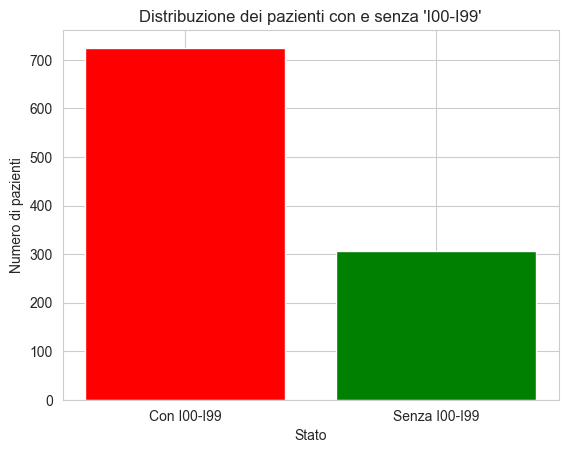

In [92]:
# Verificare se 'I00-I99' è presente in 'diagnosis_categories' e mappare i valori in 1 e 0
patients_shapelet_df['label'] = patients_shapelet_df['diagnosis_categories'].apply(lambda x: 1 if 'I00-I99' in x else 0)

# Contare quanti pazienti hanno 'I00-I99' nei diagnosis_categories
count_has_I00_I99 = patients_shapelet_df['label'].sum()

# Contare quanti non hanno 'I00-I99'
count_no_I00_I99 = len(patients_shapelet_df) - count_has_I00_I99

# Stampare i risultati
print(f"Numero di pazienti con 'I00-I99': {count_has_I00_I99}")
print(f"Numero di pazienti senza 'I00-I99': {count_no_I00_I99}")

# Visualizzare con un grafico a barre
counts = [count_has_I00_I99, count_no_I00_I99]
labels = ['Con I00-I99', 'Senza I00-I99']

plt.bar(labels, counts, color=['red', 'green'])
plt.title("Distribuzione dei pazienti con e senza 'I00-I99'")
plt.xlabel("Stato")
plt.ylabel("Numero di pazienti")
plt.show()


In [93]:
# Colonne che vuoi eliminare
columns_to_drop = [
    'study_id', 'diagnosis', 'gender', 'age', 'dod', 'age_range', 'diagnosis_categories',
    'num_categories', 'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
    'o2sat_mean', 'mean_arterial_pressure_min', 'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
    'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean', 'temperature_class_mean',
    'temperature_class_min', 'temperature_class_max', 'o2sat_class_mean', 'o2sat_class_min',
    'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_min', 'mean_arterial_pressure_class_max',
    'RR_HR_ratio_class_mean', 'RR_HR_ratio_class_min', 'RR_HR_ratio_class_max', 'age_range_class'
]

# Tieni solo le colonne presenti nel DataFrame
columns_to_drop = [col for col in columns_to_drop if col in patients_shapelet_df.columns]

# Elimina le colonne
patients_shapelet_df.drop(columns=columns_to_drop, inplace=True)


C:\Users\ironl\AppData\Local\Temp\ipykernel_25212\4257309737.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  patients_shapelet_df.drop(columns=columns_to_drop, inplace=True)


In [94]:
patients_shapelet_df


,subject_id,label
0,10000032,1
1,10000117,1
2,10000764,1
3,10000980,1
4,10001176,1
...,...,...
1038,10275673,1
1039,10275681,1
1040,10275752,1
1041,10275937,1


In [95]:
# Estrai i subject_id presenti in patients_shapelet_df
valid_subject_ids = set(patients_shapelet_df['subject_id'].astype(str))

# Filtra df_name e df_ts per mantenere solo le time series valide
df_name = [name for name in df_name if name in valid_subject_ids]
df_ts = [df for name, df in zip(df_name, df_ts) if name in valid_subject_ids]

# Verifica che il numero di elementi filtrati sia corretto
print(f"Time series filtrate: {len(df_ts)}")
df_name[-1]

Time series filtrate: 1031


'10276425'

#### ShapeletModel (crasha)

In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow.keras.optimizers
from tslearn.shapelets import ShapeletModel, grabocka_params_to_shapelet_size_dict
from tslearn.preprocessing import TimeSeriesScalerMinMax
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# --- STEP 1: Caricamento delle time series e delle etichette ---
# df_ts contiene le time series di ogni paziente
# patients_df contiene i subject_id e le label (0 = sano, 1 = malato)

# Ordina le time series in base all'ordine dei subject_id in patients_df
# df_ts_sorted = [df for subject_id in patients_df['subject_id'] for df in df_ts if subject_id in df.columns]

# Estrai le etichette (label)
y = patients_shapelet_df['label'].values

# --- STEP 2: Preparazione delle time series per il modello ---
# Converti le time series in un array numpy di forma (n_pazienti, n_record, n_lead)
X = np.array([df.values.T for df in df_ts])  # Transpose per ottenere (records, leads)
print("STEP 2 DONE")
# Normalizzazione delle time series
scaler = TimeSeriesScalerMinMax()
X = scaler.fit_transform(X)

# Suddivisione in train e test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# --- STEP 3: Calcolo delle shapelet sizes ---
n_ts, ts_sz, n_features = X_train.shape
n_classes = len(set(y_train))

shapelet_sizes = grabocka_params_to_shapelet_size_dict(n_ts=n_ts, ts_sz=ts_sz, n_classes=n_classes, l=0.1, r=1)
print("STEP 3 DONE: grabocka_params_to_shapelet_size_dict")
# --- STEP 4: Creazione del modello Shapelet ---
shp_clf = ShapeletModel(n_shapelets_per_size=shapelet_sizes,
                        optimizer="sgd",
                        weight_regularizer=.01,
                        max_iter=200,
                        verbose=1)

# Addestramento del modello
shp_clf.fit(X_train, y_train)
print("STEP 4 DONE: ShapeletModel")

# --- STEP 5: Predizione e valutazione ---
predicted_labels = shp_clf.predict(X_test)
accuracy = accuracy_score(y_test, predicted_labels)

# Stampa dei risultati
print(f"Correct classification rate: {accuracy:.2f}")

# --- STEP 6: Visualizzazione delle shapelet trovate ---
predicted_locations = shp_clf.locate(X_test)
ts_id = 0
plt.figure()
n_shapelets = sum(shapelet_sizes.values())
plt.title(f"Example locations of shapelet matches ({n_shapelets} shapelets extracted)")

plt.plot(X_test[ts_id].ravel())
for idx_shp, shp in enumerate(shp_clf.shapelets_):
    t0 = predicted_locations[ts_id, idx_shp]
    plt.plot(np.arange(t0, t0 + len(shp)), shp, linewidth=2)
plt.show()
# 6h41m

STEP 2 DONE
STEP 3 DONE: grabocka_params_to_shapelet_size_dict


C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\tslearn\shapelets\shapelets.py:354: FutureWarning: The default value for 'scale' is set to False in version 0.4 to ensure backward compatibility, but is likely to change in a future version.
  warnings.warn("The default value for 'scale' is set to False "


MemoryError: Unable to allocate 4.47 GiB for an array with shape (10000, 12, 5000) and data type float64

### Shapelet Discovery (altro approccio)

In [100]:
import pandas as pd
import numpy as np
import stumpy
import matplotlib.pyplot as plt

# Lista dei lead dell'ECG
leads = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

# Dizionario per salvare le shapelet features
shapelet_features = {f'shapelet_feature_{lead}': [] for lead in leads}

# Calcolo delle shapelet features per ogni paziente
for idx, (name, ts) in enumerate(zip(df_name, df_ts)):
    subject_id = str(name)

    # Controlla se il subject_id è valido
    if subject_id not in patients_shapelet_df['subject_id'].astype(str).values:
        continue

    print(f"{idx} | Processing subject_id: {subject_id}")

    for lead in leads:
        # Controlla se il lead esiste nel dataset
        if lead not in ts.columns:
            shapelet_features[f'shapelet_feature_{lead}'].append(np.nan)
            continue

        # Estrai la time series per il lead corrente
        signal = ts[lead].values

        # Calcola il Matrix Profile usando STUMPY
        window_size = 400
        mp = stumpy.stump(signal, m=window_size)

        # Usa il valore minimo del Matrix Profile come feature
        min_mp_distance = np.min(mp[:, 0])
        shapelet_features[f'shapelet_feature_{lead}'].append(min_mp_distance)

# Aggiungi le shapelet features al DataFrame dei pazienti
for lead in leads:
    patients_shapelet_df[f'shapelet_feature_{lead}'] = shapelet_features[f'shapelet_feature_{lead}']

# Reorder delle colonne per avere la label come ultima colonna
columns_order = [col for col in patients_shapelet_df.columns if col != 'label'] + ['label']
patients_shapelet_df = patients_shapelet_df[columns_order]

# Salva il file aggiornato in un CSV
output_file = "ecg_classification_with_leads_shapelets.csv"
patients_shapelet_df.to_csv(output_file, index=False)

print(f"Updated classification file saved to: {output_file}")
print(patients_shapelet_df.head())
#29 min

0 | Processing subject_id: 10000032
1 | Processing subject_id: 10000117
2 | Processing subject_id: 10000764
3 | Processing subject_id: 10000980
4 | Processing subject_id: 10001176
5 | Processing subject_id: 10001217
6 | Processing subject_id: 10001401
7 | Processing subject_id: 10002221
8 | Processing subject_id: 10002430
9 | Processing subject_id: 10002528
10 | Processing subject_id: 10002557
11 | Processing subject_id: 10002755
12 | Processing subject_id: 10002807
13 | Processing subject_id: 10002869
14 | Processing subject_id: 10003019
15 | Processing subject_id: 10003052
16 | Processing subject_id: 10003199
17 | Processing subject_id: 10003203
18 | Processing subject_id: 10003299
19 | Processing subject_id: 10003400
20 | Processing subject_id: 10003757
21 | Processing subject_id: 10004322
22 | Processing subject_id: 10004457
23 | Processing subject_id: 10004606
24 | Processing subject_id: 10004720
25 | Processing subject_id: 10005606
26 | Processing subject_id: 10005866
27 | Proces

C:\Users\ironl\AppData\Local\Temp\ipykernel_25212\3448941077.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  patients_shapelet_df[f'shapelet_feature_{lead}'] = shapelet_features[f'shapelet_feature_{lead}']
C:\Users\ironl\AppData\Local\Temp\ipykernel_25212\3448941077.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  patients_shapelet_df[f'shapelet_feature_{lead}'] = shapelet_features[f'shapelet_feature_{lead}']
C:\Users\ironl\AppData\Local\Temp\ipykernel_25212\3448941077.py:41: SettingWithCopyWarning

In [107]:
print(patients_shapelet_df.head())

   subject_id  shapelet_feature_I  shapelet_feature_II  shapelet_feature_III  \
0    10000032            3.556281             1.344149              2.801188   
1    10000117            5.271336             2.324999              2.476823   
2    10000764            1.616630             1.880516              4.977532   
3    10000980            1.368895             1.920713              3.261146   
4    10001176            3.204771             2.764200              3.638480   

   shapelet_feature_aVR  shapelet_feature_aVL  shapelet_feature_aVF  \
0              2.039354              4.248524              1.702951   
1              2.675525              4.424040              2.310968   
2              1.555099              3.761462              2.979628   
3              1.368829              1.940495              3.117317   
4              4.697190              2.956202              3.345413   

   shapelet_feature_V1  shapelet_feature_V2  shapelet_feature_V3  \
0             0.849871  

In [3]:
patients_shapelet_df = pd.read_csv("ecg_classification_with_leads_shapelets.csv")
patients_df = pd.read_csv("../datasets/general_patients_TAB.csv")

In [4]:
# Associa la colonna 'age' di patients_df a patients_shapelet_df usando 'subject_id' come chiave
patients_shapelet_df = patients_shapelet_df.merge(
    patients_df[['subject_id', 'age']],
    on='subject_id',
    how='left'
)

# Riordina le colonne per mantenere 'label' come ultima colonna
columns_order = [col for col in patients_shapelet_df.columns if col != 'label'] + ['label']
patients_shapelet_df = patients_shapelet_df[columns_order]

# Mostra le prime righe del DataFrame aggiornato
print(patients_shapelet_df.head())


   subject_id  shapelet_feature_I  shapelet_feature_II  shapelet_feature_III  \
0    10000032            3.556281             1.344149              2.801188   
1    10000117            5.271336             2.324999              2.476823   
2    10000764            1.616630             1.880516              4.977532   
3    10000980            1.368895             1.920713              3.261146   
4    10001176            3.204771             2.764200              3.638480   

   shapelet_feature_aVR  shapelet_feature_aVL  shapelet_feature_aVF  \
0              2.039354              4.248524              1.702951   
1              2.675525              4.424040              2.310968   
2              1.555099              3.761462              2.979628   
3              1.368829              1.940495              3.117317   
4              4.697190              2.956202              3.345413   

   shapelet_feature_V1  shapelet_feature_V2  shapelet_feature_V3  \
0             0.849871  

### Classificazione delle time series con e senza SMOTE

In [34]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc,
)
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt

def classisifaction(USE_SMOTE, test_size):
    # Definisci i classificatori da testare
    classifiers = {
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=335, class_weight={0: 1.8, 1: 1}, random_state=42),
        "AdaBoost": AdaBoostClassifier(n_estimators=100, algorithm='SAMME', random_state=42),
        "Logistic Regression": LogisticRegression(max_iter=500),
        "k-NN": KNeighborsClassifier(n_neighbors=5),
    }
    
    # Definisci le shapelet features da utilizzare
    leads_features = [f'shapelet_feature_{lead}' for lead in ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']]
    
    # Seleziona le features e le etichette
    X = patients_shapelet_df[leads_features + ['age']]
    y = patients_shapelet_df['label']
    
    # Suddividi il dataset in training e testing
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)
    
    # --- Applica SMOTE se USE_SMOTE è True ---
    if USE_SMOTE:
        print("\nApplying SMOTE to balance classes...")
        smote = SMOTE(random_state=42)
        X_train, y_train = smote.fit_resample(X_train, y_train)
    else:
        print("\nSMOTE not applied. Using original training set.")
    
    # Crea figure per i paragoni affiancati
    fig_confusion, axs_confusion = plt.subplots(1, len(classifiers), figsize=(25, 5))
    fig_pr, axs_pr = plt.subplots(1, len(classifiers), figsize=(25, 5))
    fig_roc, axs_roc = plt.subplots(1, len(classifiers), figsize=(25, 5))
    
    # Itera sui diversi classificatori
    for i, (name, clf) in enumerate(classifiers.items()):
        print(f"\nProcessing classifier: {name}")
    
        # Addestra il classificatore
        clf.fit(X_train, y_train)
    
        # Effettua le predizioni
        y_pred = clf.predict(X_test)
    
        # Valuta il classificatore
        accuracy = accuracy_score(y_test, y_pred)
        print(f"Accuracy for {name}: {accuracy:.3f}")
        print(classification_report(y_test, y_pred))
    
        # --- Confusion Matrix ---
        cm = confusion_matrix(y_test, y_pred)
        cm_percent = cm / cm.sum() * 100
        disp = ConfusionMatrixDisplay(confusion_matrix=cm_percent, display_labels=["NO I00_I99", "YES I00_I99"])
        disp.plot(cmap='Blues', values_format='.2f', ax=axs_confusion[i])
        axs_confusion[i].set_title(f"Confusion Matrix ({name})")
    
        # --- Precision-Recall Curve ---
        if hasattr(clf, "predict_proba"):
            y_scores = clf.predict_proba(X_test)[:, 1]
            precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
            pr_auc = auc(recall, precision)
            axs_pr[i].plot(recall, precision, label=f"PR AUC = {pr_auc:.3f}")
            axs_pr[i].set_title(f"PR Curve ({name})")
            axs_pr[i].set_xlabel("Recall")
            axs_pr[i].set_ylabel("Precision")
            axs_pr[i].legend()
    
        # --- ROC Curve ---
        if hasattr(clf, "predict_proba"):
            roc_auc = roc_auc_score(y_test, y_scores)
            fpr, tpr, _ = roc_curve(y_test, y_scores)
            axs_roc[i].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
            axs_roc[i].plot([0, 1], [0, 1], linestyle='--', color='gray')
            axs_roc[i].set_title(f"ROC Curve ({name})")
            axs_roc[i].set_xlabel("False Positive Rate")
            axs_roc[i].set_ylabel("True Positive Rate")
            axs_roc[i].legend()
    
    # Mostra i grafici affiancati con più spazio tra il titolo e i grafici
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.4, wspace=0.4, top=0.85)
    
    fig_confusion.suptitle(f"Confusion Matrices for Different Classifiers {test_size}\n", fontsize=16)
    fig_pr.suptitle(f"Precision-Recall Curves for Different Classifiers {test_size}\n", fontsize=16)
    fig_roc.suptitle(f"ROC Curves for Different Classifiers {test_size}\n", fontsize=16)
    
    plt.show()



Testing on test size: 0.2

SMOTE not applied. Using original training set.

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.729
              precision    recall  f1-score   support

           0       0.51      0.47      0.49        57
           1       0.81      0.83      0.82       150

    accuracy                           0.73       207
   macro avg       0.66      0.65      0.65       207
weighted avg       0.72      0.73      0.73       207


Processing classifier: Random Forest
Accuracy for Random Forest: 0.802
              precision    recall  f1-score   support

           0       0.75      0.42      0.54        57
           1       0.81      0.95      0.87       150

    accuracy                           0.80       207
   macro avg       0.78      0.68      0.71       207
weighted avg       0.79      0.80      0.78       207


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.802
              precision    recall  f1-score   support

         

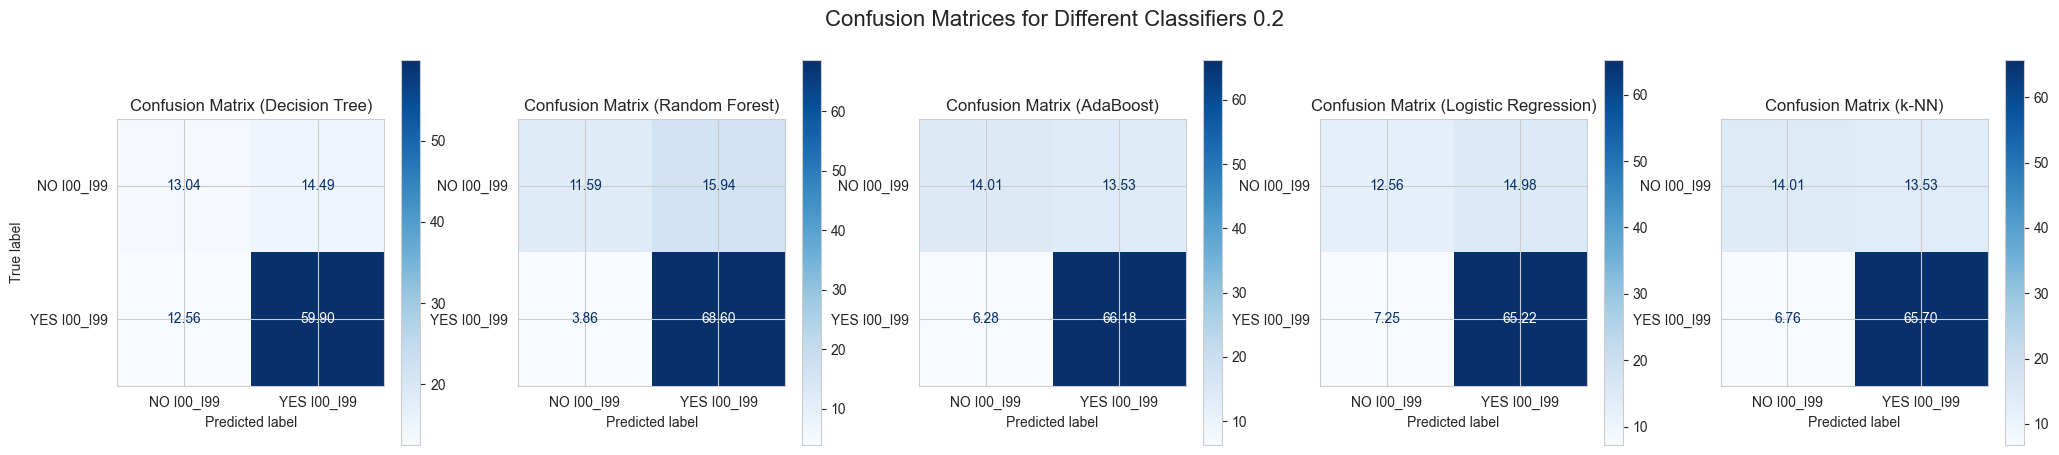

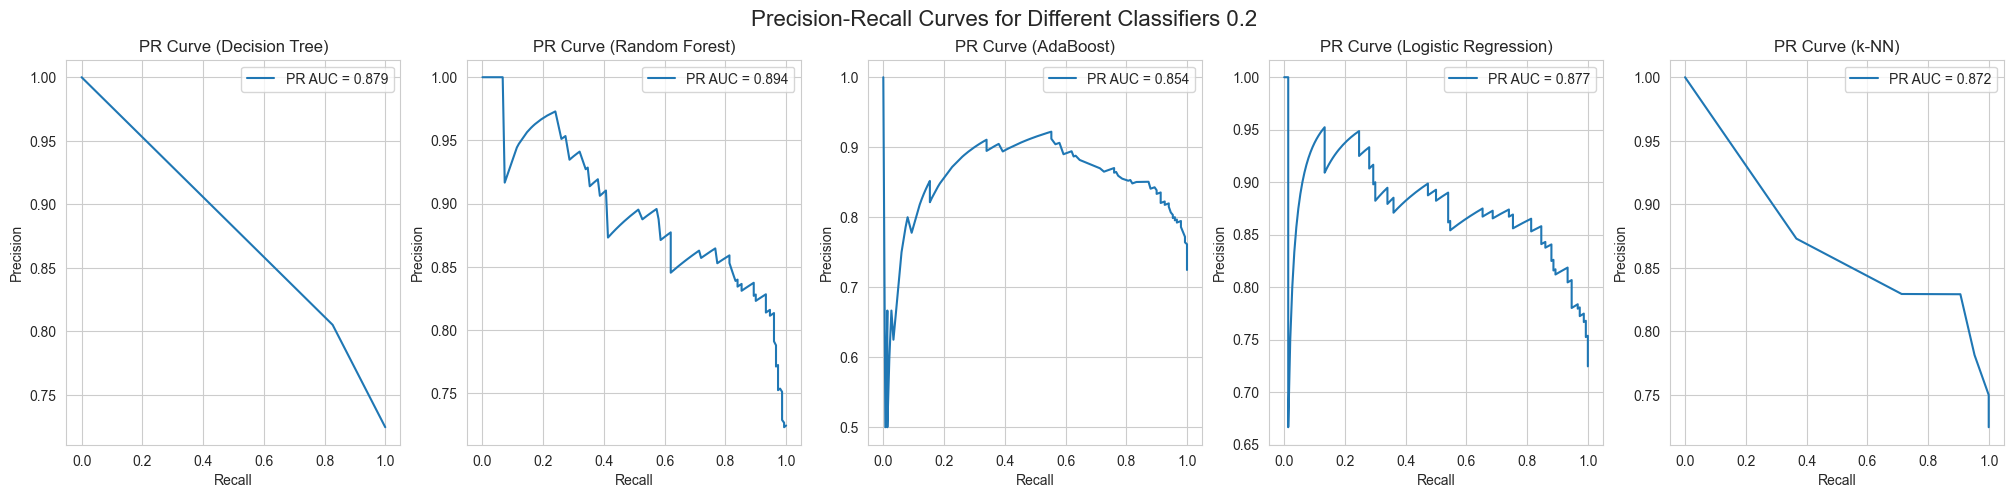

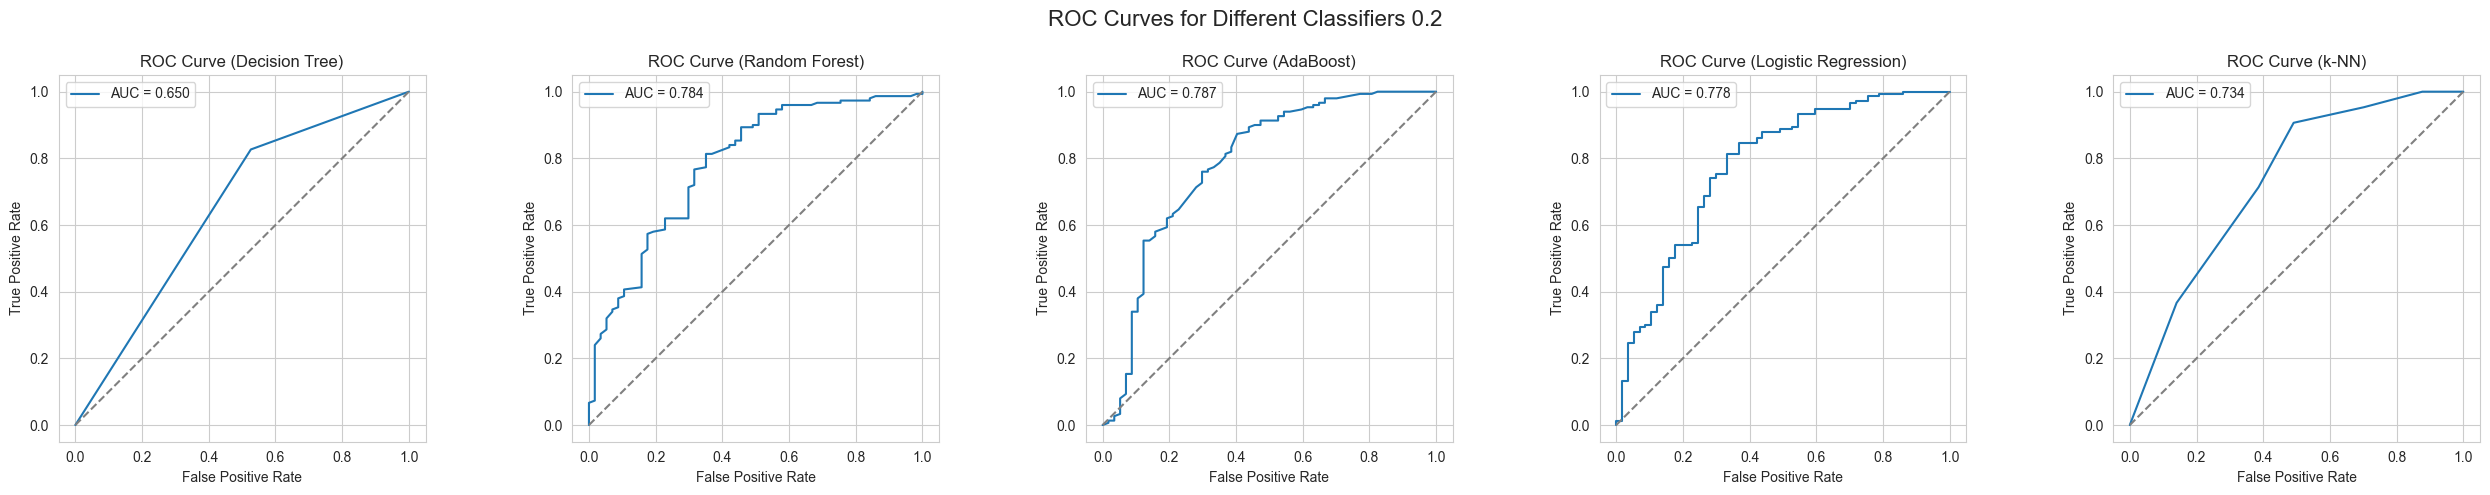


Testing on test size: 0.25

SMOTE not applied. Using original training set.

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.717
              precision    recall  f1-score   support

           0       0.48      0.47      0.47        70
           1       0.80      0.81      0.81       188

    accuracy                           0.72       258
   macro avg       0.64      0.64      0.64       258
weighted avg       0.72      0.72      0.72       258


Processing classifier: Random Forest
Accuracy for Random Forest: 0.798
              precision    recall  f1-score   support

           0       0.74      0.40      0.52        70
           1       0.81      0.95      0.87       188

    accuracy                           0.80       258
   macro avg       0.77      0.67      0.70       258
weighted avg       0.79      0.80      0.78       258


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.810
              precision    recall  f1-score   support

        

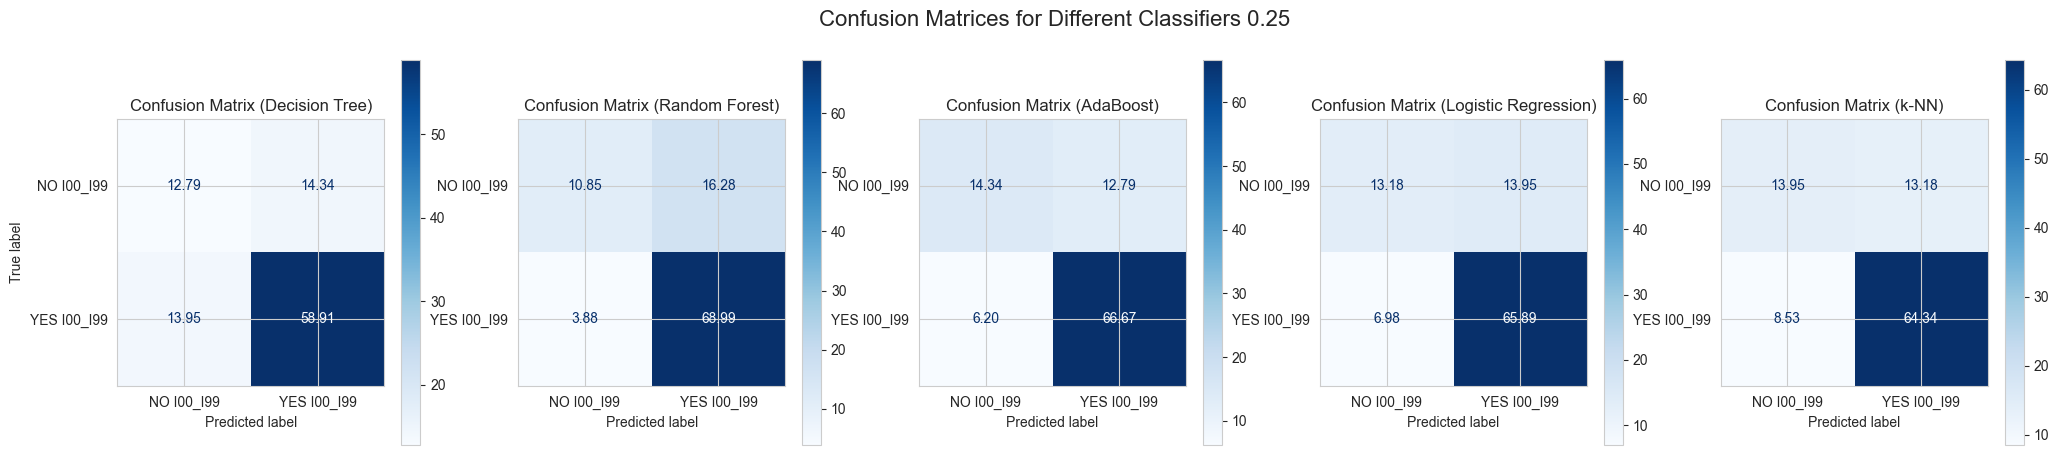

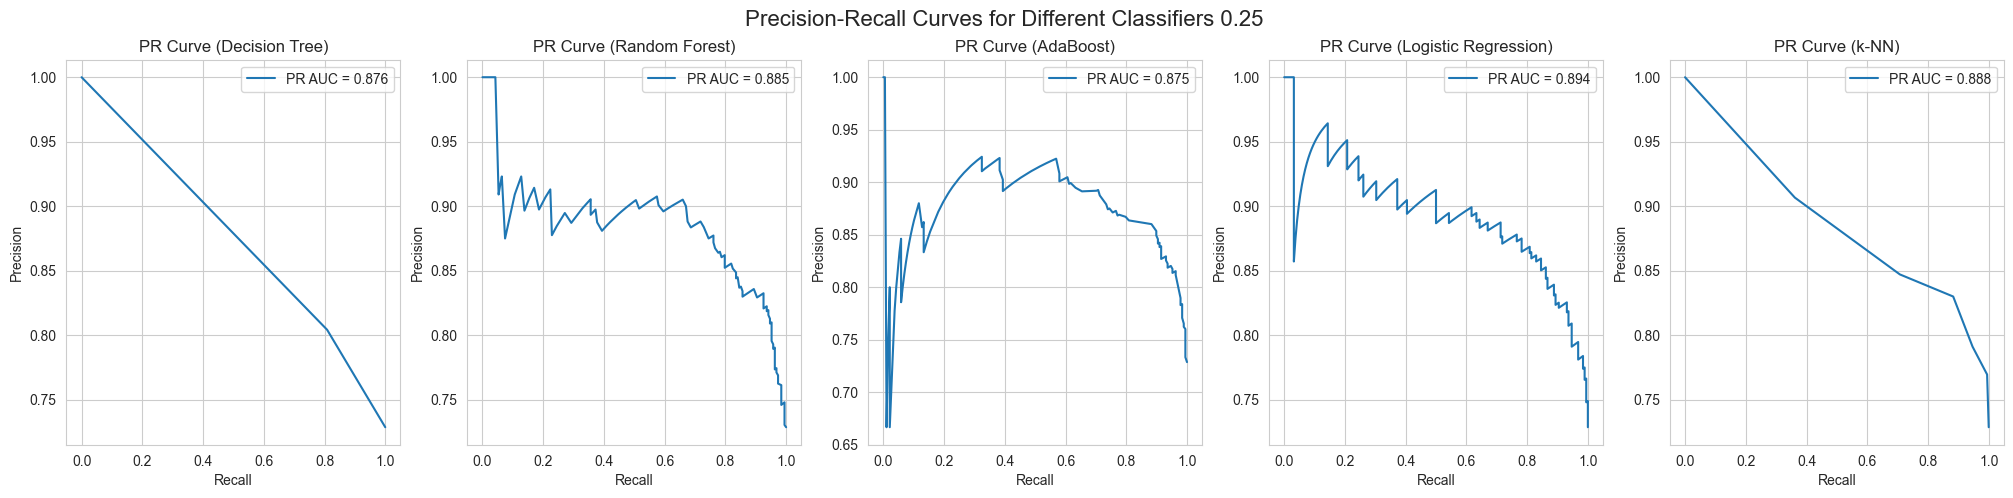

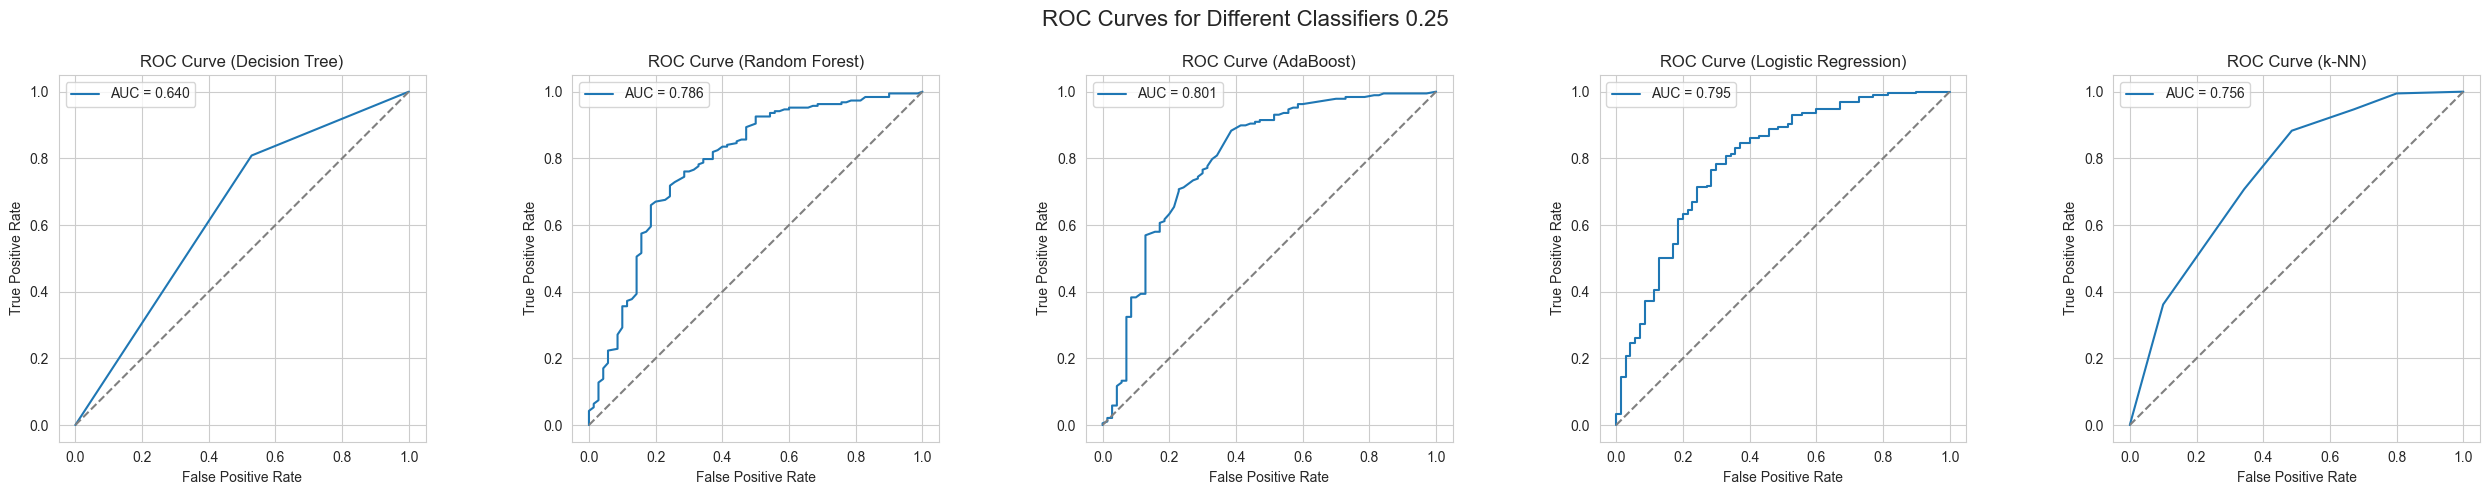


Testing on test size: 0.3

SMOTE not applied. Using original training set.

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.694
              precision    recall  f1-score   support

           0       0.46      0.51      0.48        87
           1       0.80      0.77      0.78       223

    accuracy                           0.69       310
   macro avg       0.63      0.64      0.63       310
weighted avg       0.70      0.69      0.70       310


Processing classifier: Random Forest
Accuracy for Random Forest: 0.790
              precision    recall  f1-score   support

           0       0.71      0.43      0.53        87
           1       0.81      0.93      0.86       223

    accuracy                           0.79       310
   macro avg       0.76      0.68      0.70       310
weighted avg       0.78      0.79      0.77       310


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.803
              precision    recall  f1-score   support

         

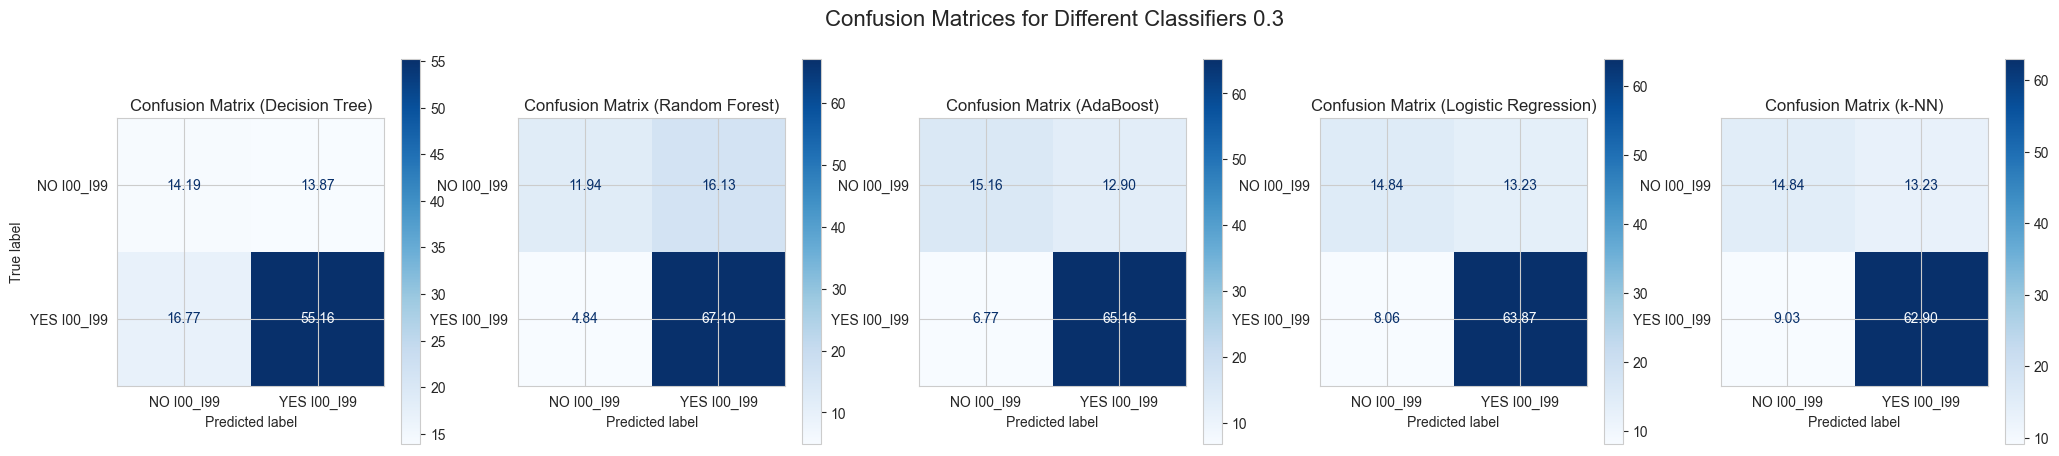

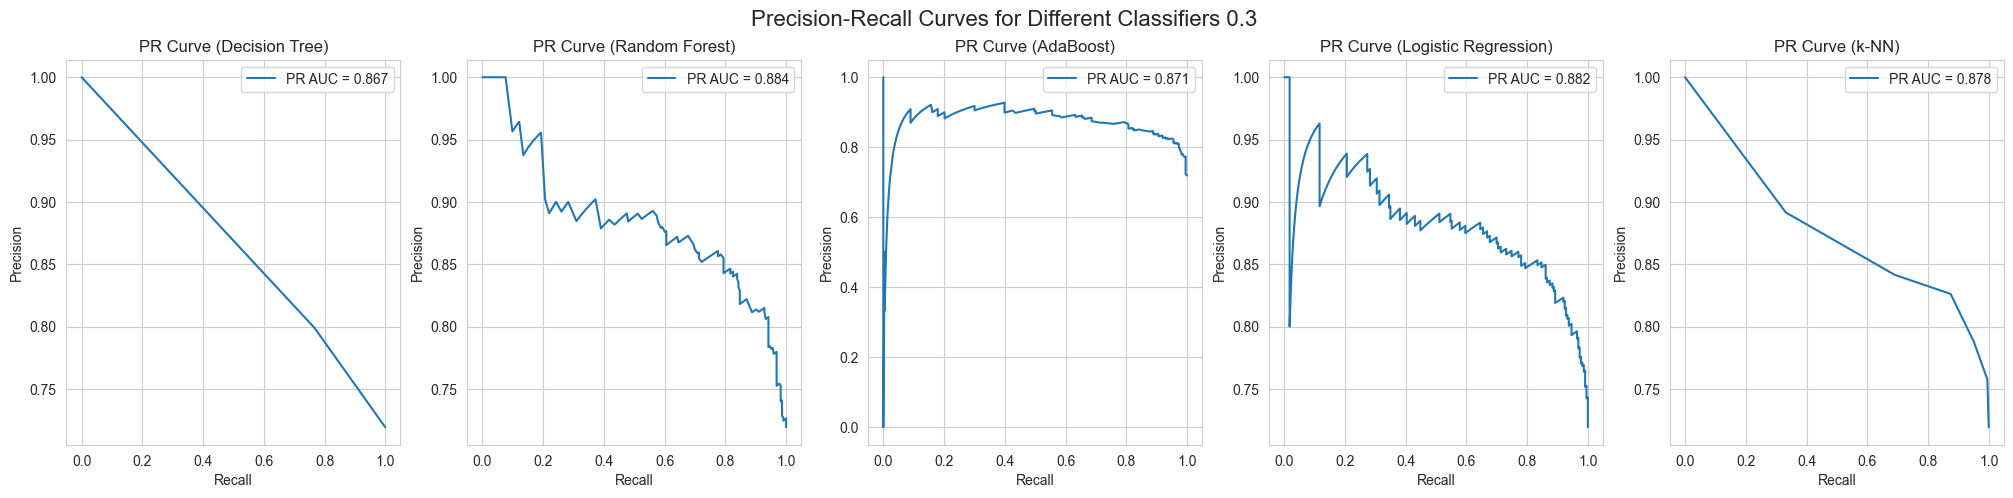

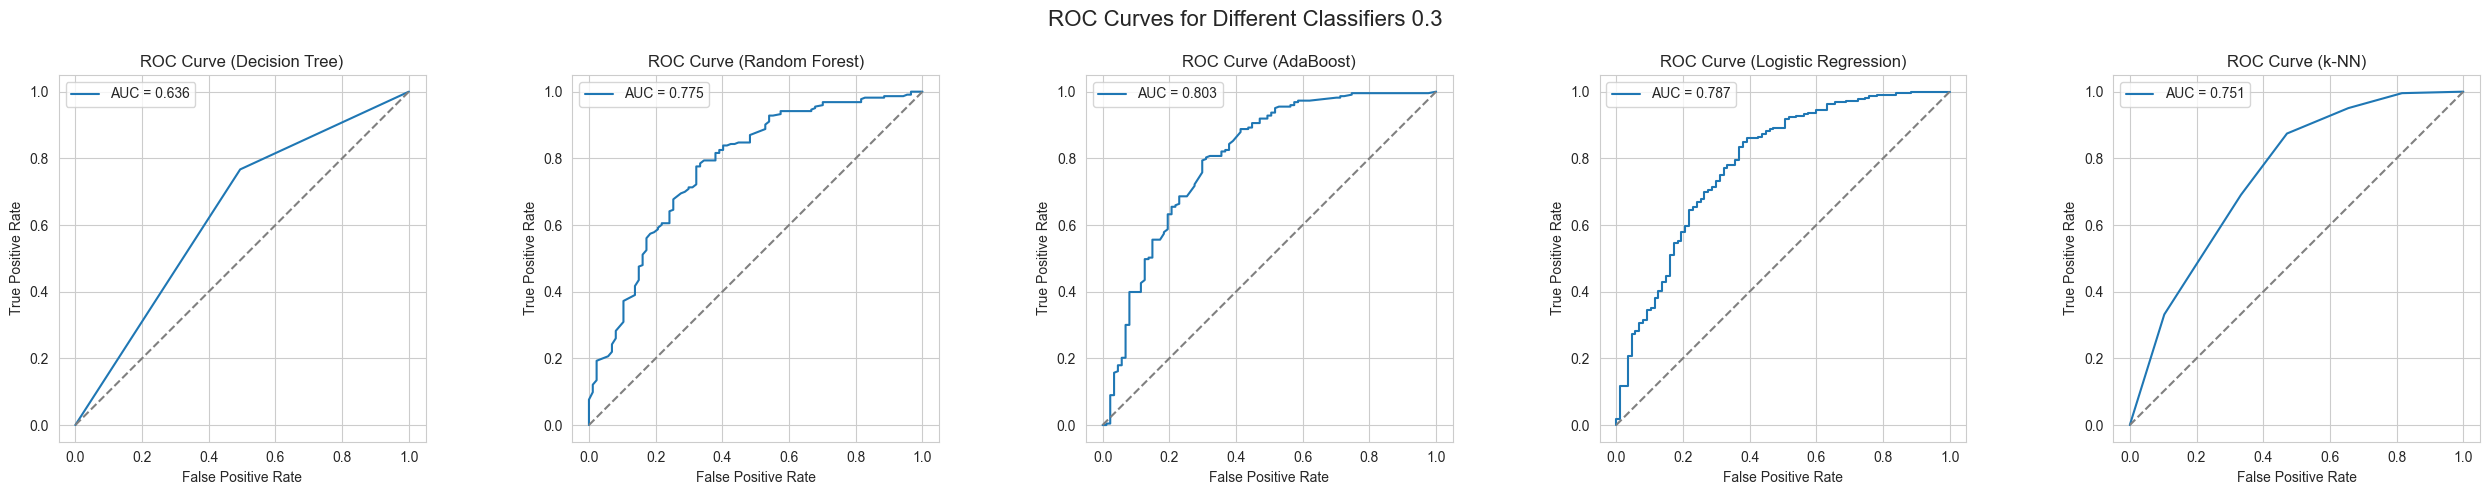

In [35]:
# SMOTE DISATTIVO
test_sizes = [0.20, 0.25, 0.30]
for test_size in test_sizes:
    print("\nTesting on test size:", test_size)
    classisifaction(False, test_size)


Testing on test size: 0.2

Applying SMOTE to balance classes...

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.662
              precision    recall  f1-score   support

           0       0.40      0.46      0.43        57
           1       0.78      0.74      0.76       150

    accuracy                           0.66       207
   macro avg       0.59      0.60      0.59       207
weighted avg       0.68      0.66      0.67       207


Processing classifier: Random Forest
Accuracy for Random Forest: 0.807
              precision    recall  f1-score   support

           0       0.68      0.56      0.62        57
           1       0.84      0.90      0.87       150

    accuracy                           0.81       207
   macro avg       0.76      0.73      0.74       207
weighted avg       0.80      0.81      0.80       207


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.773
              precision    recall  f1-score   support

           0       0

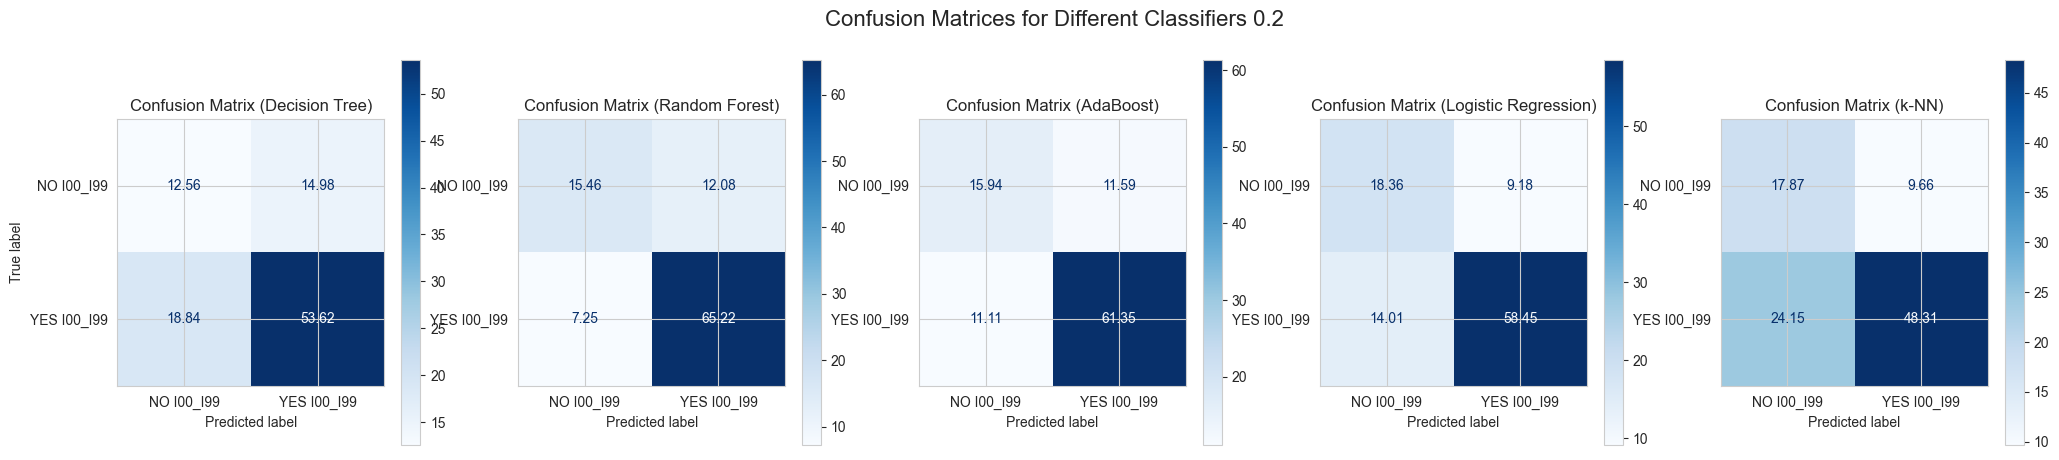

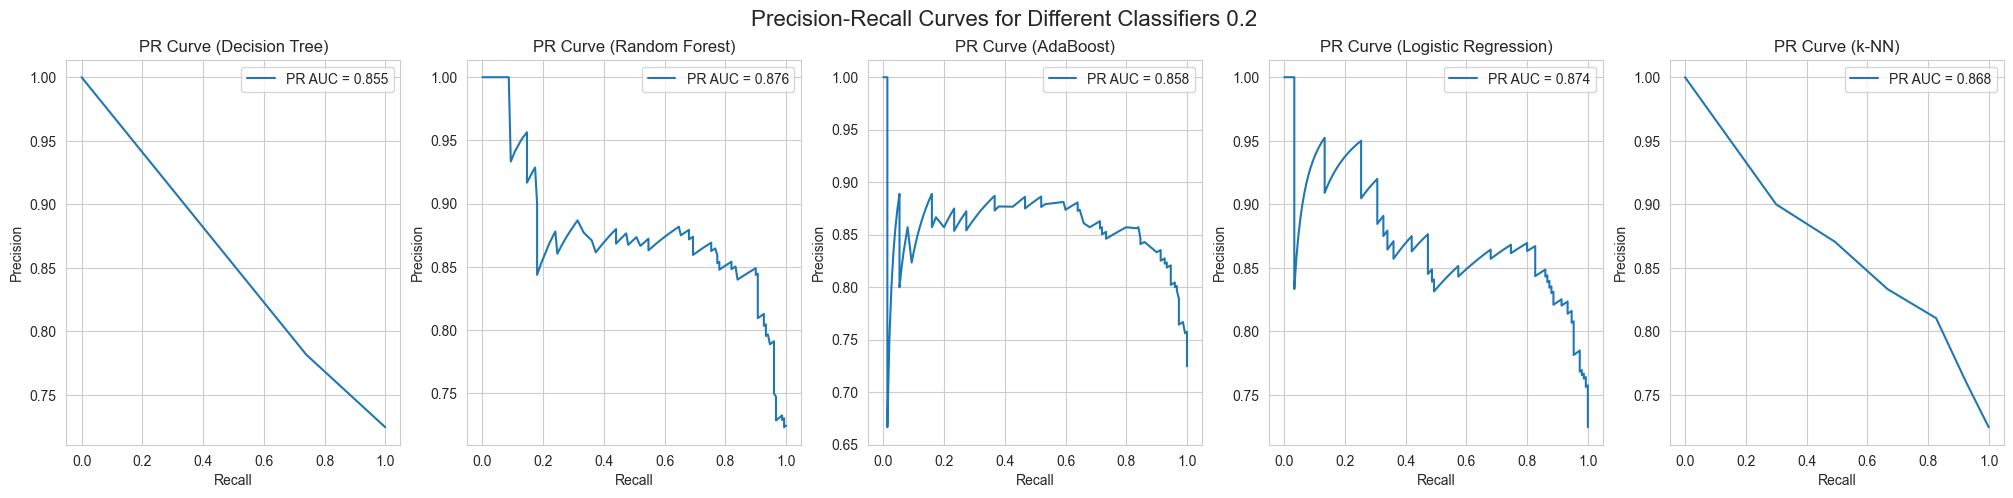

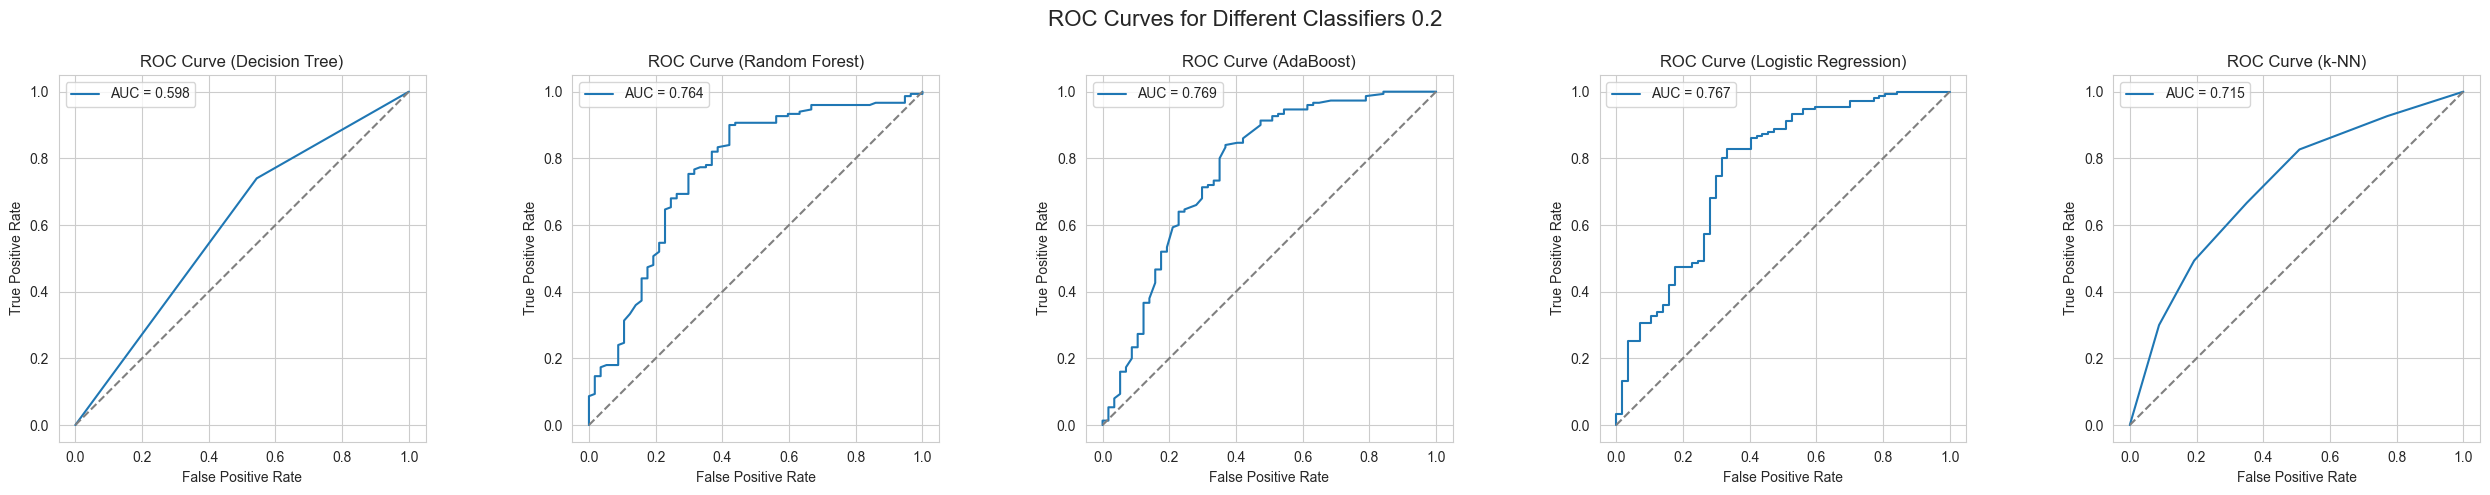


Testing on test size: 0.25

Applying SMOTE to balance classes...

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.682
              precision    recall  f1-score   support

           0       0.43      0.54      0.48        70
           1       0.81      0.73      0.77       188

    accuracy                           0.68       258
   macro avg       0.62      0.64      0.63       258
weighted avg       0.71      0.68      0.69       258


Processing classifier: Random Forest
Accuracy for Random Forest: 0.795
              precision    recall  f1-score   support

           0       0.64      0.56      0.60        70
           1       0.84      0.88      0.86       188

    accuracy                           0.79       258
   macro avg       0.74      0.72      0.73       258
weighted avg       0.79      0.79      0.79       258


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.752
              precision    recall  f1-score   support

           0       

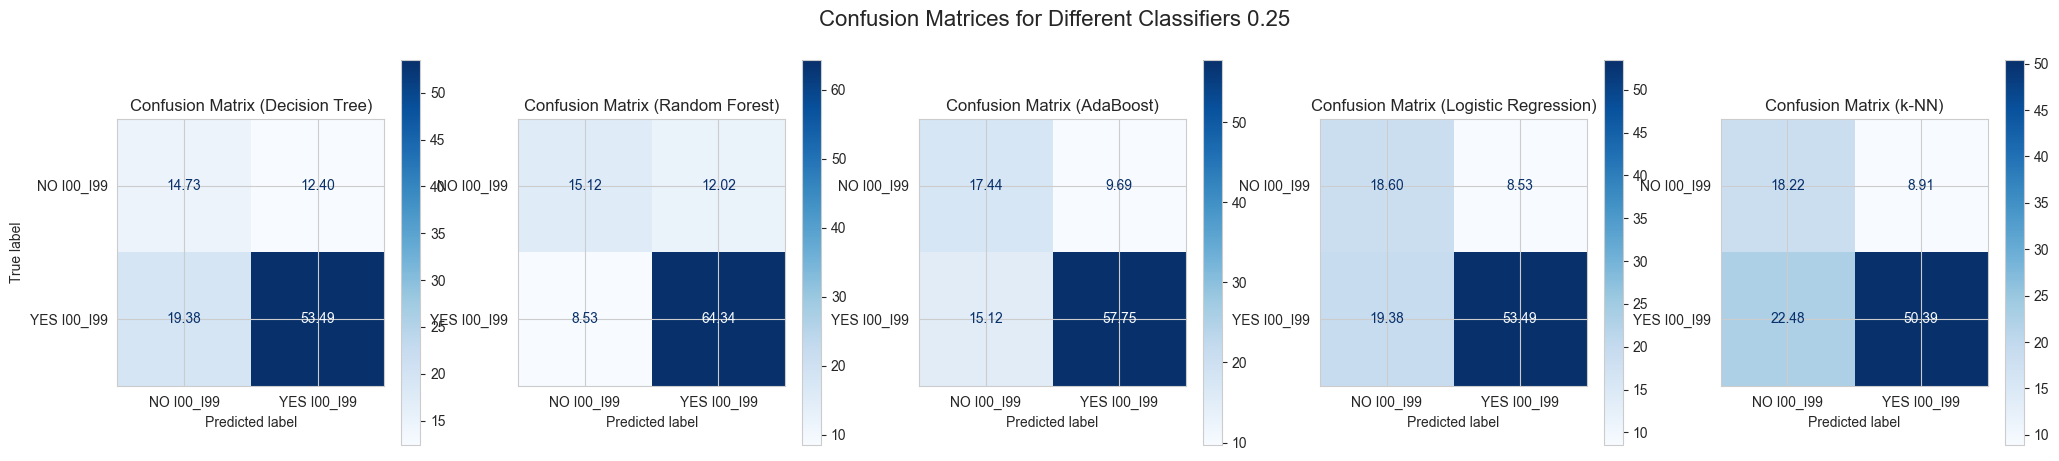

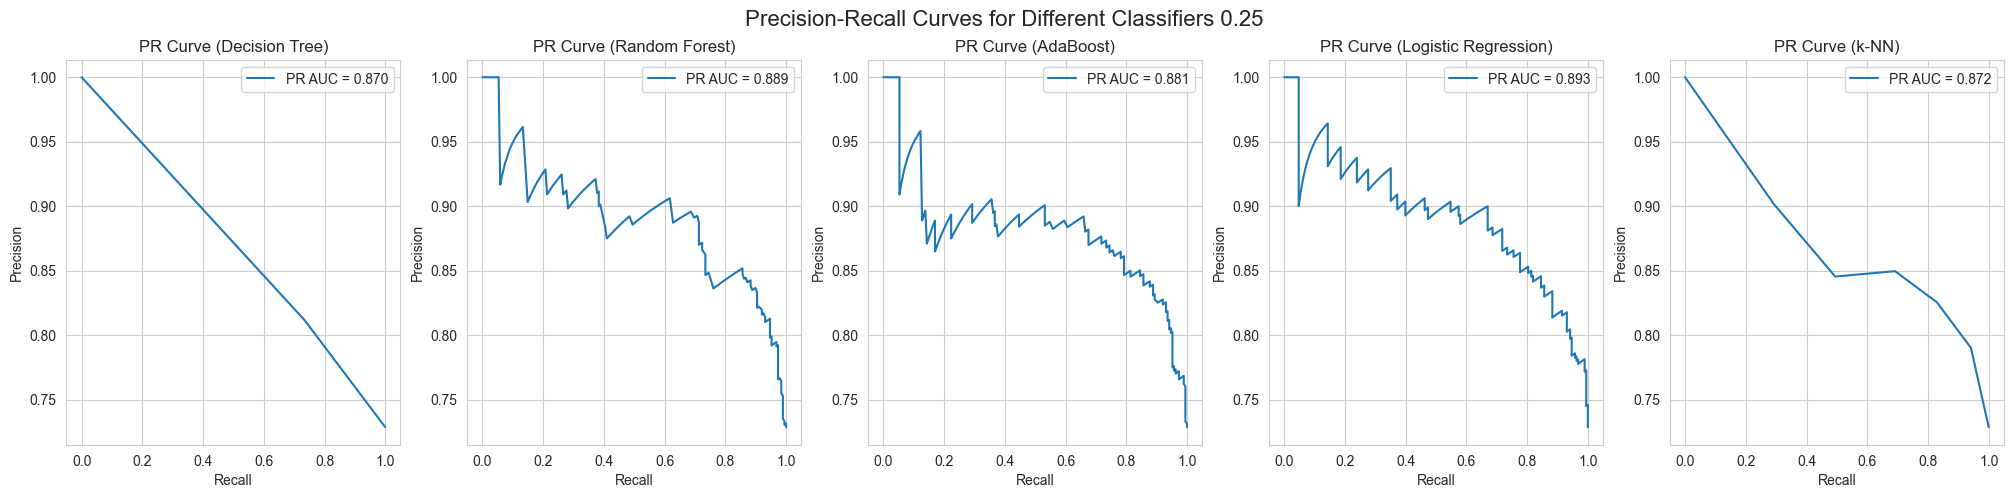

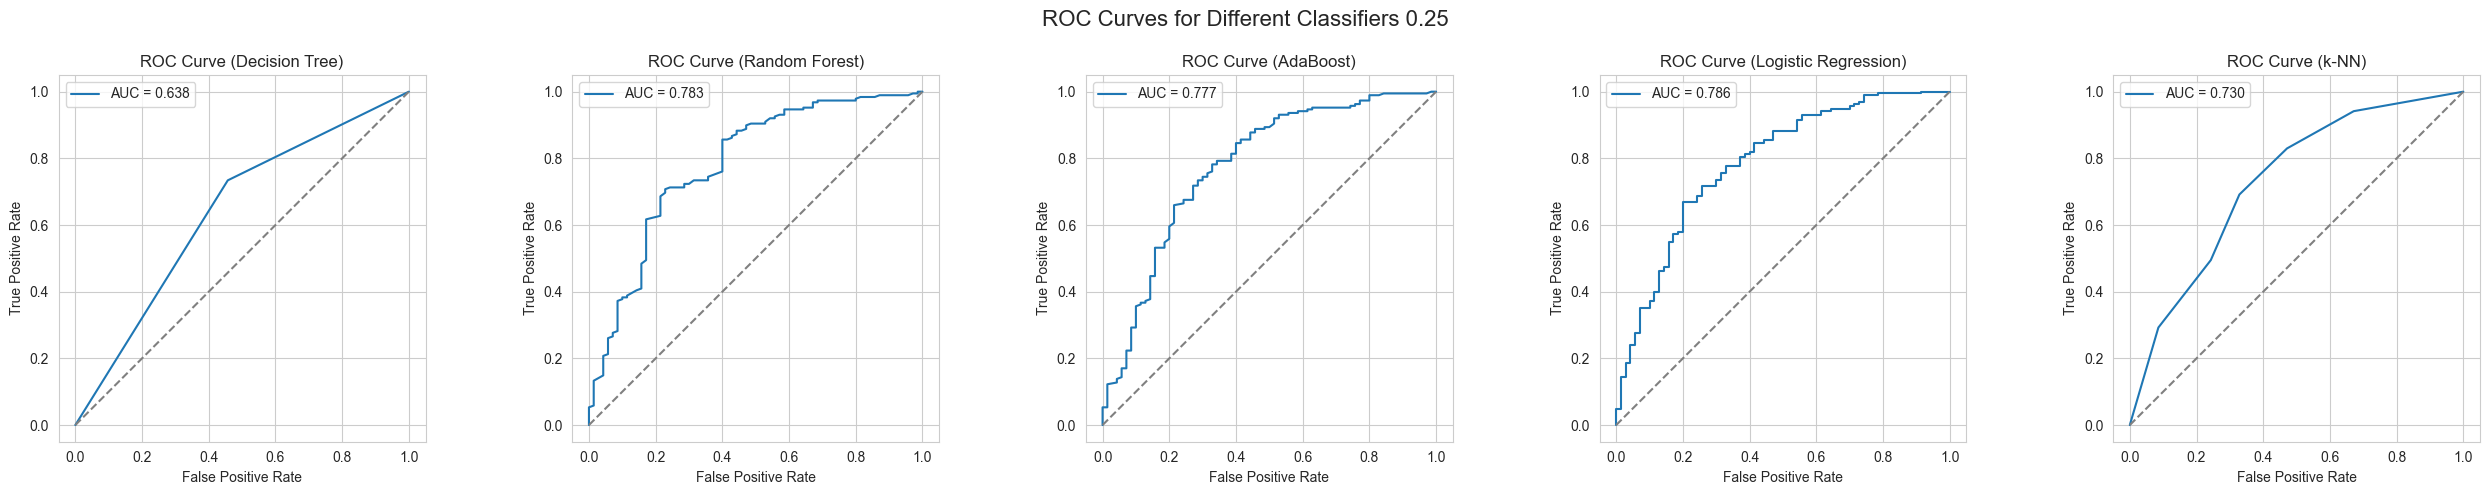


Testing on test size: 0.3

Applying SMOTE to balance classes...

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.668
              precision    recall  f1-score   support

           0       0.43      0.54      0.48        87
           1       0.80      0.72      0.76       223

    accuracy                           0.67       310
   macro avg       0.61      0.63      0.62       310
weighted avg       0.70      0.67      0.68       310


Processing classifier: Random Forest
Accuracy for Random Forest: 0.765
              precision    recall  f1-score   support

           0       0.59      0.53      0.56        87
           1       0.82      0.86      0.84       223

    accuracy                           0.76       310
   macro avg       0.71      0.69      0.70       310
weighted avg       0.76      0.76      0.76       310


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.758
              precision    recall  f1-score   support

           0       0

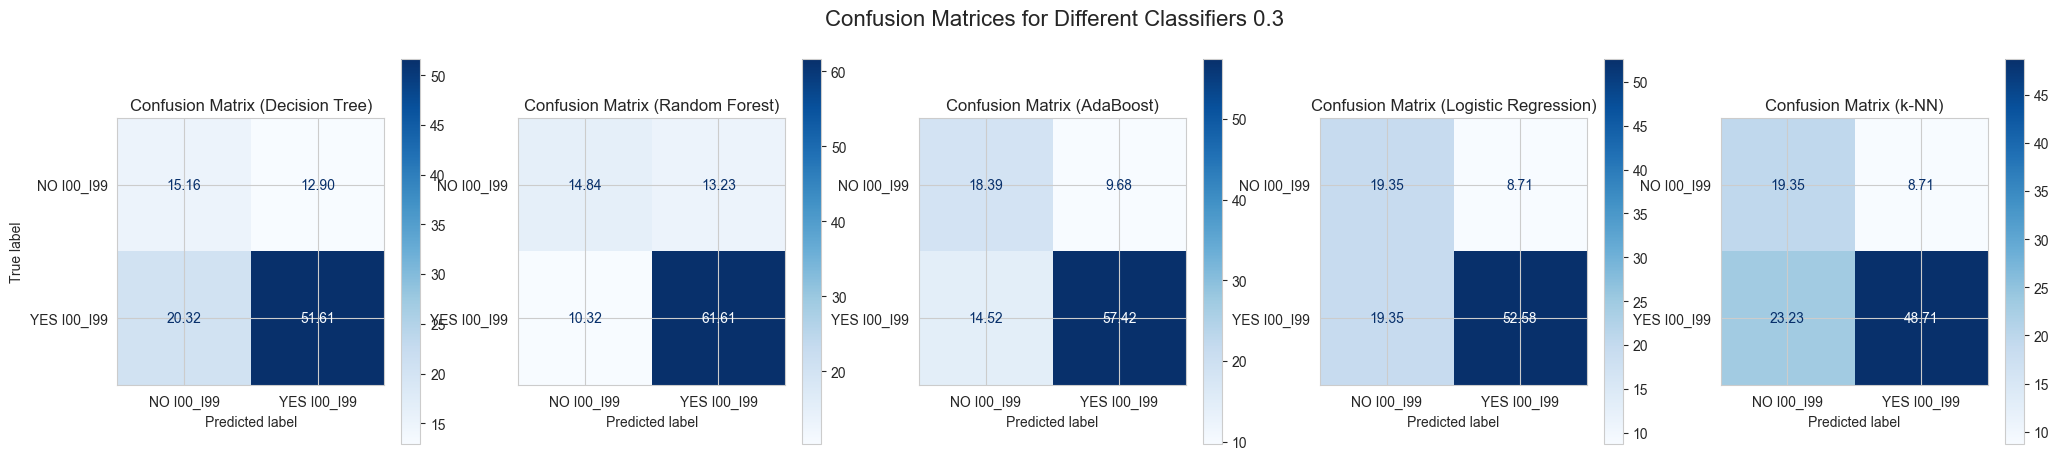

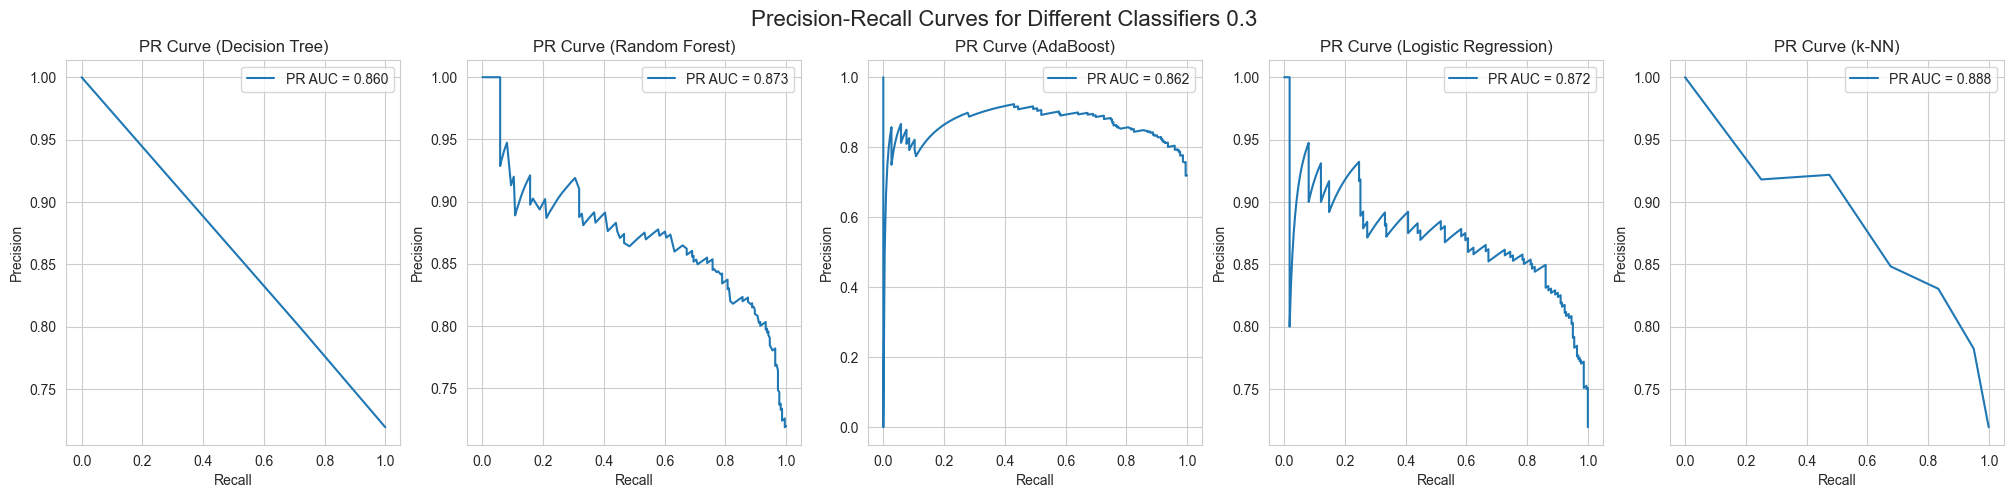

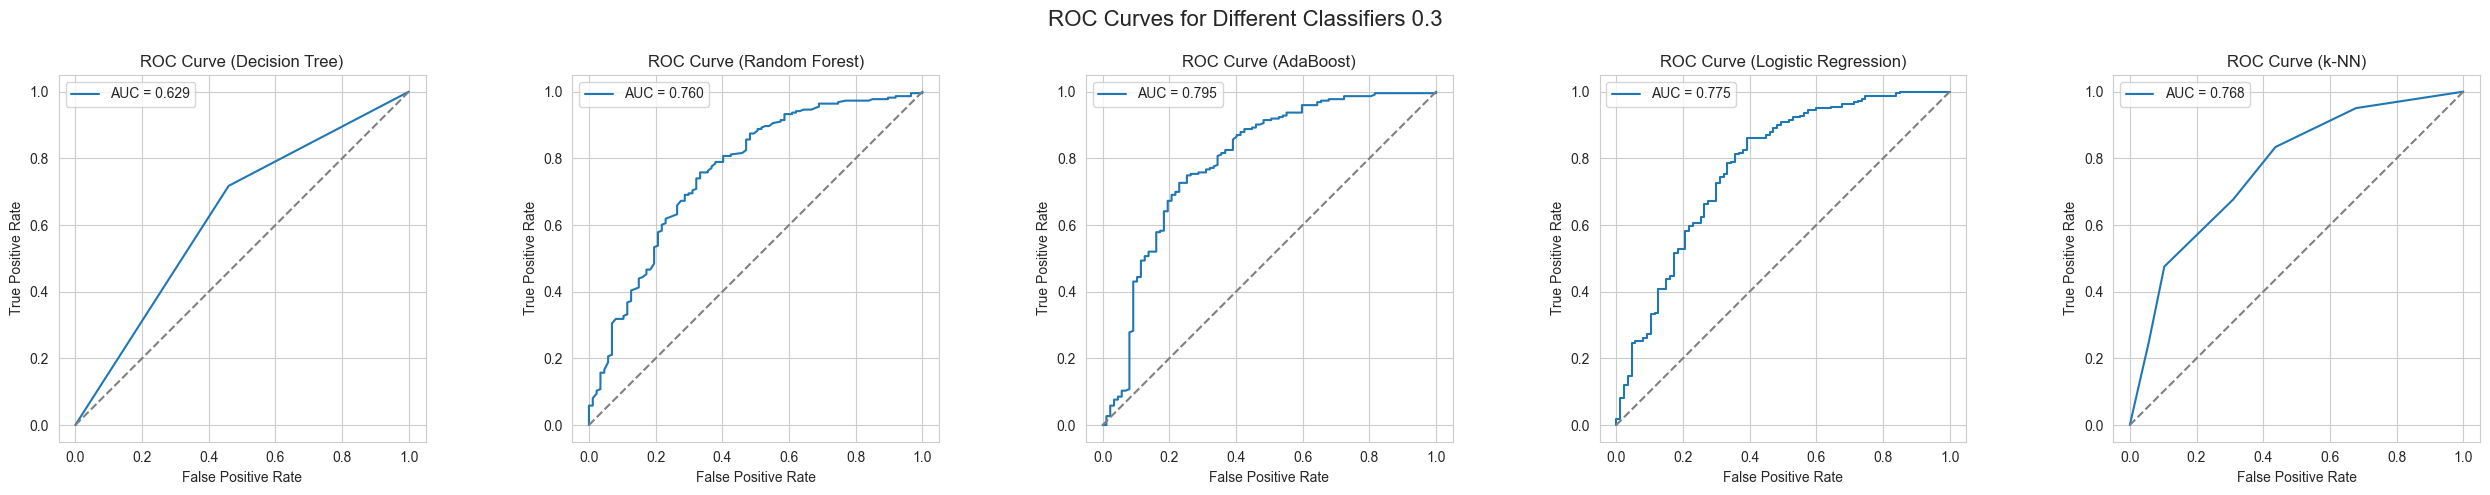

In [37]:
# SMOTE ATTIVO
test_sizes = [0.20, 0.25, 0.30]
for test_size in test_sizes:
    print("\nTesting on test size:", test_size)
    classisifaction(True, test_size)